In [1]:
from pathlib import Path
import os, sys, json, math, random, re, shutil, time
from collections import Counter, defaultdict
from tqdm import tqdm
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# CHANGE ONLY THIS
# ============================================================
LANG = "hi"       # "hi" or "ne"

INPUT_ROOT = Path("/kaggle/input")
DATASET_ROOT = INPUT_ROOT / "hindi-nepali-sft"
MODEL_ROOT = INPUT_ROOT / "lma-hindi"

OUT = Path("/kaggle/working") / f"phase3_{LANG}"
SRC_OUT = OUT / "src"
CKPT_OUT = OUT / "checkpoints"
PLOT_OUT = OUT / "plots"
METRIC_OUT = OUT / "metrics"
LOG_OUT = OUT / "logs"

for d in (OUT, SRC_OUT, CKPT_OUT, PLOT_OUT, METRIC_OUT, LOG_OUT):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Language:", "Hindi" if LANG == "hi" else "Nepali")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def first_existing(*paths):
    for p in paths:
        p = Path(p)
        if p.exists():
            return p
    return None

def find_input_file(name, preferred=None):
    preferred = Path(preferred) if preferred else None
    if preferred is not None and preferred.exists():
        return preferred

    matches = list(INPUT_ROOT.rglob(name))
    if not matches:
        raise FileNotFoundError(f"Could not find {name} anywhere under {INPUT_ROOT}")
    return matches[0]

LANG_INFO = {
    "hi": {
        "name": "Hindi",
        "dataset_dir": DATASET_ROOT / "hindi" / "reasoning" / "data",
        "tokenizer_name": "hindi_bpe16k",
    },
    "ne": {
        "name": "Nepali",
        "dataset_dir": DATASET_ROOT / "nepali" / "reasoning" / "data",
        "tokenizer_name": "nepali_bpe16k",
    },
}
INFO = LANG_INFO[LANG]

TRAIN_JSONL = find_input_file(
    "train.jsonl",
    INFO["dataset_dir"] / "train.jsonl"
)
VAL_JSONL = find_input_file(
    "val.jsonl",
    INFO["dataset_dir"] / "val.jsonl"
)
TEST_JSONL = find_input_file(
    "test.jsonl",
    INFO["dataset_dir"] / "test.jsonl"
)

MODEL_PY = find_input_file("model.py", MODEL_ROOT / "model.py")
TOKENIZERS_PY = find_input_file("tokenizers.py", MODEL_ROOT / "tokenizers.py")
CKPT_PATH = find_input_file("last.pt", MODEL_ROOT / "ckpt" / "last.pt")

TOKENIZER_PKL = find_input_file(
    f"{INFO['tokenizer_name']}.pkl",
    MODEL_ROOT / "tokenizer" / f"{INFO['tokenizer_name']}.pkl"
)

print("\nInputs:")
for name, path in {
    "model.py": MODEL_PY,
    "tokenizers.py": TOKENIZERS_PY,
    "checkpoint": CKPT_PATH,
    "tokenizer": TOKENIZER_PKL,
    "train": TRAIN_JSONL,
    "val": VAL_JSONL,
    "test": TEST_JSONL,
}.items():
    print(f"{name:12s}: {path}")

print("\nOutputs:")
print(OUT)

Language: Hindi
Device: cuda
GPU: Tesla T4

Inputs:
model.py    : /kaggle/input/notebooks/gulgulasaur/lma-hindi/model.py
tokenizers.py: /kaggle/input/notebooks/gulgulasaur/lma-hindi/tokenizers.py
checkpoint  : /kaggle/input/notebooks/gulgulasaur/lma-hindi/ckpt/last.pt
tokenizer   : /kaggle/input/notebooks/gulgulasaur/lma-hindi/tokenizer/hindi_bpe16k.pkl
train       : /kaggle/input/datasets/gulgulasaur/hindi-nepali-sft/hindi/reasoning/data/train.jsonl
val         : /kaggle/input/datasets/gulgulasaur/hindi-nepali-sft/hindi/reasoning/data/val.jsonl
test        : /kaggle/input/datasets/gulgulasaur/hindi-nepali-sft/hindi/reasoning/data/test.jsonl

Outputs:
/kaggle/working/phase3_hi


In [2]:
# Copy the student's original implementation into writable working storage.
# We do not modify the source files.
shutil.copy2(MODEL_PY, SRC_OUT / "model.py")
shutil.copy2(TOKENIZERS_PY, SRC_OUT / "tokenizers.py")

sys.path.insert(0, str(SRC_OUT))

from model import GPTLanguageModel
from tokenizers import customBPE

print("Loaded GPTLanguageModel and customBPE from the supplied Phase 2 files.")

Loaded GPTLanguageModel and customBPE from the supplied Phase 2 files.


## 1. Load the fixed tokenizer

The Phase 3 protocol requires the language's existing tokenizer/vocabulary to remain fixed. We only load it here. No tokenizer training occurs.

In [3]:
tokenizer = customBPE()
tokenizer.load(str(TOKENIZER_PKL))

VOCAB = tokenizer.vocab
ID_TO_TOKEN = {int(i): t for t, i in VOCAB.items()}

PAD_ID = VOCAB.get("<pad>")
BOS_ID = VOCAB.get("<bos>")
EOS_ID = VOCAB.get("<eos>")
BOW_ID = VOCAB.get("▁")
UNK_ID = VOCAB.get("UNK", 0)

if PAD_ID is None:
    raise ValueError("Tokenizer does not contain <pad>.")
if BOW_ID is None:
    raise ValueError("Tokenizer does not contain the ▁ boundary token.")

VOCAB_SIZE = max(ID_TO_TOKEN) + 1

print("Tokenizer:", TOKENIZER_PKL)
print("Vocabulary size:", VOCAB_SIZE)
print("Special IDs:", {
    "PAD": PAD_ID,
    "BOS": BOS_ID,
    "EOS": EOS_ID,
    "BOW": BOW_ID,
    "UNK": UNK_ID,
})

Tokenizer: /kaggle/input/notebooks/gulgulasaur/lma-hindi/tokenizer/hindi_bpe16k.pkl
Vocabulary size: 14548
Special IDs: {'PAD': 14544, 'BOS': 14545, 'EOS': 14546, 'BOW': 14547, 'UNK': 0}


## 2. Tokenization glue used by Phase 2

`customBPE.tokenize()` returns subword pieces but does not preserve whitespace. Phase 2 therefore used the `▁` boundary token around each pre-tokenized word. The same encoding/decoding convention is reused here.

In [4]:
def encode_text(text, add_bos=False, add_eos=False):
    ids = []
    if add_bos and BOS_ID is not None:
        ids.append(BOS_ID)

    words = tokenizer.pre_tokenizer.tokenize(text)
    for word in words:
        ids.append(BOW_ID)

        pieces = tokenizer._token_cache.get(word)
        if pieces is None:
            pieces = tokenizer.tokenize(word)

        for piece in pieces:
            ids.append(VOCAB.get(piece, UNK_ID))

    if add_eos and EOS_ID is not None:
        ids.append(EOS_ID)

    return ids

def decode_ids(ids):
    words = []
    current = ""

    for raw_id in ids:
        token = ID_TO_TOKEN.get(int(raw_id), "")

        if token == "▁":
            if current:
                words.append(current)
            current = ""
        elif token in {"<pad>", "<bos>", "<eos>"}:
            continue
        else:
            current += token

    if current:
        words.append(current)

    return " ".join(words)

sample = "भारत एक महान देश है।"
encoded = encode_text(sample)
print("Sample:", sample)
print("Encoded:", encoded[:30])
print("Decoded:", decode_ids(encoded))

Sample: भारत एक महान देश है।
Encoded: [14547, 273, 14547, 113, 14547, 8212, 14547, 1517, 14547, 311]
Decoded: भारत एक महान देश है।


## 3. Load the Phase 2 checkpoint

The checkpoint created by the Phase 2 notebook contains the architecture fields:

- `vocab_size`
- `d_model`
- `n_heads`
- `n_layers`
- `d_ff`
- `step`
- `model`

We reconstruct the exact architecture from the checkpoint instead of manually guessing it.

In [5]:
raw_ckpt = torch.load(CKPT_PATH, map_location="cpu")

if "model" not in raw_ckpt:
    raise KeyError(f"Expected checkpoint key 'model'. Found: {list(raw_ckpt.keys())}")

def ckpt_value(name, fallback=None):
    if name in raw_ckpt:
        return raw_ckpt[name]
    if "config" in raw_ckpt and isinstance(raw_ckpt["config"], dict):
        return raw_ckpt["config"].get(name, fallback)
    return fallback

CKPT_VOCAB_SIZE = int(ckpt_value("vocab_size", 0))
D_MODEL = int(ckpt_value("d_model", 0))
N_HEADS = int(ckpt_value("n_heads", 0))
N_LAYERS = int(ckpt_value("n_layers", 0))
D_FF = int(ckpt_value("d_ff", 0))

state = raw_ckpt["model"]

# Fallbacks from tensor shapes if required.
if not CKPT_VOCAB_SIZE:
    CKPT_VOCAB_SIZE = state["token_emb.weight"].shape[0]
if not D_MODEL:
    D_MODEL = state["token_emb.weight"].shape[1]
if not N_LAYERS:
    N_LAYERS = max(
        int(k.split(".")[1]) for k in state if k.startswith("blocks.") and k.endswith(".ln1.weight")
    ) + 1
if not D_FF:
    D_FF = state["blocks.0.ffn.linear1.weight"].shape[0]

CONTEXT_LEN = int(state["pos_emb.weight"].shape[0])

print("Checkpoint:", CKPT_PATH)
print("Pretraining step:", raw_ckpt.get("step", "unknown"))
print("Architecture:")
print(f"  vocab_size = {CKPT_VOCAB_SIZE:,}")
print(f"  d_model    = {D_MODEL}")
print(f"  n_heads    = {N_HEADS}")
print(f"  n_layers   = {N_LAYERS}")
print(f"  d_ff       = {D_FF}")
print(f"  context    = {CONTEXT_LEN}")
print(f"  parameters = {sum(v.numel() for v in state.values()):,}")

if CKPT_VOCAB_SIZE != VOCAB_SIZE:
    raise ValueError(
        f"Tokenizer/checkpoint vocabulary mismatch: tokenizer={VOCAB_SIZE}, checkpoint={CKPT_VOCAB_SIZE}"
    )

Checkpoint: /kaggle/input/notebooks/gulgulasaur/lma-hindi/ckpt/last.pt
Pretraining step: 15270
Architecture:
  vocab_size = 14,548
  d_model    = 576
  n_heads    = 4
  n_layers   = 4
  d_ff       = 2304
  context    = 256
  parameters = 33,125,248


In [6]:
model = GPTLanguageModel(
    vocab_size=CKPT_VOCAB_SIZE,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    d_ff=D_FF,
    context_len=CONTEXT_LEN,
    dropout=0.1,
    pad_token_id=PAD_ID,
)

missing, unexpected = model.load_state_dict(state, strict=True)
model.to(DEVICE)

print("Checkpoint loaded successfully.")
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Checkpoint loaded successfully.
Missing keys: []
Unexpected keys: []
Trainable parameters: 24,483,456


## 4. Load the synthetic reasoning dataset

The current generator produces 15 task families (comparison, transitive,
arithmetic, percentage, ratio, algebra, unit_conversion, speed_distance,
physics_fma, physics_density, physics_work, multi_hop, logic, common_sense,
counting) with exact train/validation/test sizes. Answers are no longer
uniformly short numbers: comparison/transitive tasks answer with a name,
logic tasks answer "yes"/"no", direction tasks answer "increase"/"decrease",
and common_sense tasks answer with a short natural-language phrase. Each
example also carries a `difficulty` tier (easy/medium/hard).

We retain the metadata for per-task and per-difficulty evaluation and
leakage/error analysis.


In [7]:
def read_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

train_rows = read_jsonl(TRAIN_JSONL)
val_rows = read_jsonl(VAL_JSONL)
test_rows = read_jsonl(TEST_JSONL)

print("Dataset sizes:")
print("  train:", len(train_rows))
print("  val:  ", len(val_rows))
print("  test: ", len(test_rows))

for split_name, rows in [("train", train_rows), ("val", val_rows), ("test", test_rows)]:
    counts = Counter(r["task_type"] for r in rows)
    print(f"\n{split_name} task distribution:")
    for k, v in sorted(counts.items()):
        print(f"  {k:15s}: {v:,}")

print("\nExample:")
print(json.dumps(train_rows[0], ensure_ascii=False, indent=2))

Dataset sizes:
  train: 15000
  val:   2000
  test:  1000

train task distribution:
  algebra        : 1,200
  arithmetic     : 1,050
  common_sense   : 1,050
  comparison     : 1,050
  counting       : 600
  logic          : 1,050
  multi_hop      : 1,350
  percentage     : 1,050
  physics_density: 750
  physics_fma    : 900
  physics_work   : 750
  ratio          : 1,050
  speed_distance : 1,050
  transitive     : 1,050
  unit_conversion: 1,050

val task distribution:
  algebra        : 160
  arithmetic     : 140
  common_sense   : 140
  comparison     : 140
  counting       : 80
  logic          : 140
  multi_hop      : 180
  percentage     : 140
  physics_density: 100
  physics_fma    : 120
  physics_work   : 100
  ratio          : 140
  speed_distance : 140
  transitive     : 140
  unit_conversion: 140

test task distribution:
  algebra        : 80
  arithmetic     : 70
  common_sense   : 70
  comparison     : 70
  counting       : 40
  logic          : 70
  multi_hop      : 90
  

In [8]:
# Basic dataset sanity checks.
assert len(train_rows) == 15000, f"Expected 15000 train examples, got {len(train_rows)}"
assert len(val_rows) == 2000, f"Expected 2000 val examples, got {len(val_rows)}"
assert len(test_rows) == 1000, f"Expected 1000 test examples, got {len(test_rows)}"

all_ids = [r["id"] for r in train_rows + val_rows + test_rows]
assert len(all_ids) == len(set(all_ids)), "Duplicate IDs detected."

for row in train_rows + val_rows + test_rows:
    assert isinstance(row["question"], str) and row["question"].strip()
    assert isinstance(row["answer"], str) and row["answer"].strip()

print("Dataset validation passed.")

Dataset validation passed.


## 5. SFT formatting and loss masking

Each example becomes:

```text
<question>
उत्तर: <answer>
```

The model is trained only on the answer portion.

Because `GPTLanguageModel.forward()` computes cross-entropy at the **same position** rather than shifting the targets internally, the first answer token is placed at the final prompt position:

```text
input:  prompt[0] ... prompt[p-1] answer[0] answer[1] ...
label:  PAD       ... PAD       answer[0] answer[1] ...
```

This is the correct causal-LM alignment for the supplied `model.py`.

In [9]:
ANSWER_PREFIX = "उत्तर:"

def format_example(row):
    prompt = row["question"].strip() + "\n" + ANSWER_PREFIX
    answer = row["answer"].strip()
    return prompt, answer

def make_sft_sequence(row):
    prompt, answer = format_example(row)

    prompt_ids = encode_text(prompt)
    answer_ids = encode_text(answer)

    # Need at least one target token.
    if not answer_ids:
        raise ValueError(f"Empty tokenized answer for {row['id']}")

    full_ids = prompt_ids + answer_ids

    # Model's loss is position-aligned, so target[final_prompt_position]
    # predicts the first answer token.
    labels = [PAD_ID] * max(0, len(prompt_ids) - 1) + answer_ids

    # Keep input and labels identical in length.
    labels = labels[:len(full_ids)]
    full_ids = full_ids[:len(labels)]

    return full_ids, labels

for row in train_rows[:3]:
    ids, labels = make_sft_sequence(row)
    print("\nQUESTION:", row["question"])
    print("ANSWER:  ", row["answer"])
    print("tokens:", len(ids))
    print("supervised positions:", sum(x != PAD_ID for x in labels))


QUESTION: अमित और निखिल के पास वस्तुओं की संख्या का अनुपात 4:5 है। यदि अमित के पास 36 वस्तुएँ हैं, तो निखिल के पास कितनी हैं?
ANSWER:   45
tokens: 66
supervised positions: 2

QUESTION: कंप्यूटर की ऊँचाई 72 सेंटीमीटर है, जबकि कैलकुलेटर की ऊँचाई 77 सेंटीमीटर है। कौन लंबा है?
ANSWER:   कैलकुलेटर
tokens: 53
supervised positions: 5

QUESTION: गेंद का वजन 80 किलोग्राम है और लैंप का वजन 68 किलोग्राम है। किसका वजन अधिक है?
ANSWER:   गेंद
tokens: 43
supervised positions: 2


In [10]:
MAX_SEQ_LEN = CONTEXT_LEN
BATCH_SIZE = 32
GRAD_ACCUM_STEPS = 1

def build_tensor_pair(row):
    ids, labels = make_sft_sequence(row)

    # Preserve the answer region when truncating.
    if len(ids) > MAX_SEQ_LEN:
        ids = ids[-MAX_SEQ_LEN:]
        labels = labels[-MAX_SEQ_LEN:]

    x = torch.full((MAX_SEQ_LEN,), PAD_ID, dtype=torch.long)
    y = torch.full((MAX_SEQ_LEN,), PAD_ID, dtype=torch.long)

    x[:len(ids)] = torch.tensor(ids, dtype=torch.long)
    y[:len(labels)] = torch.tensor(labels, dtype=torch.long)
    return x, y

class ReasoningDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        return build_tensor_pair(self.rows[idx])

train_ds = ReasoningDataset(train_rows)
val_ds = ReasoningDataset(val_rows)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 469
Val batches: 63


## 6. Pretrained baseline reasoning accuracy

Before updating any weights, measure exact-match reasoning accuracy on the held-out test set.

This is the key baseline for the required **pretrained vs. fine-tuned** comparison.

In [11]:
def normalize_answer(text):
    text = text.strip().lower()
    text = re.sub(r"[\s\u200b]+", " ", text)
    text = re.sub(r"[।,.!?;:]+$", "", text)
    return text.strip()

# The generator now produces much more varied answers than short numbers:
# comparison/transitive tasks answer with a name, logic tasks answer
# "yes"/"no", direction tasks answer "increase"/"decrease", and
# common_sense tasks answer with a short natural-language phrase (several
# words, e.g. "धूप वाली खुली जगह"). A fixed max_new_tokens=8 was sized for
# numeric answers only and silently truncates these longer phrase-style
# answers, which shows up as a permanent 0% on common_sense regardless of
# training. We size the generation budget from the longest tokenized gold
# answer actually present in the dataset instead of a hardcoded constant.
def answer_token_length(answer):
    return len(encode_text(answer.strip()))

MAX_ANSWER_TOKENS = max(
    answer_token_length(r["answer"]) for r in train_rows + val_rows + test_rows
)
GEN_MAX_NEW_TOKENS = MAX_ANSWER_TOKENS + 4  # small buffer for BPE/boundary quirks
print(f"Longest gold answer: {MAX_ANSWER_TOKENS} tokens -> generating up to {GEN_MAX_NEW_TOKENS} tokens")

@torch.no_grad()
def generate_answer(row, max_new_tokens=GEN_MAX_NEW_TOKENS):
    prompt, expected = format_example(row)
    prompt_ids = encode_text(prompt)

    if len(prompt_ids) >= CONTEXT_LEN:
        prompt_ids = prompt_ids[-CONTEXT_LEN:]

    x = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)

    model.eval()
    generated = model.greedy_generate(x, max_new_tokens=max_new_tokens)[0].tolist()
    continuation = generated[len(prompt_ids):]

    prediction = decode_ids(continuation)
    return prediction, expected

def exact_match(pred, gold):
    p = normalize_answer(pred)
    g = normalize_answer(gold)

    # Generation may continue beyond the exact answer. Accept the answer
    # when it appears as the first normalized phrase.
    return p == g or p.startswith(g + " ")

def evaluate_reasoning(rows, max_new_tokens=GEN_MAX_NEW_TOKENS):
    records = []

    for row in tqdm(rows):
        pred, gold = generate_answer(row, max_new_tokens=max_new_tokens)
        records.append({
            "id": row["id"],
            "task_type": row["task_type"],
            "template_id": row["template_id"],
            "difficulty": row.get("difficulty"),
            "prediction": pred,
            "answer": gold,
            "correct": exact_match(pred, gold),
        })

    overall = float(np.mean([r["correct"] for r in records]))

    per_task = {}
    for task in sorted(set(r["task_type"] for r in records)):
        subset = [r for r in records if r["task_type"] == task]
        per_task[task] = float(np.mean([r["correct"] for r in subset]))

    per_difficulty = {}
    for diff in sorted({r["difficulty"] for r in records if r["difficulty"] is not None}):
        subset = [r for r in records if r["difficulty"] == diff]
        per_difficulty[diff] = float(np.mean([r["correct"] for r in subset]))

    return overall, per_task, per_difficulty, records

baseline_acc, baseline_task_acc, baseline_difficulty_acc, baseline_records = evaluate_reasoning(test_rows)

print(f"Pretrained overall accuracy: {baseline_acc * 100:.2f}%")
for task, acc in baseline_task_acc.items():
    print(f"  {task:15s}: {acc * 100:.2f}%")

print("\nBy difficulty:")
for diff, acc in baseline_difficulty_acc.items():
    print(f"  {diff:8s}: {acc * 100:.2f}%")


Longest gold answer: 10 tokens -> generating up to 14 tokens


100%|██████████| 1000/1000 [00:36<00:00, 27.27it/s]

Pretrained overall accuracy: 0.40%
  algebra        : 0.00%
  arithmetic     : 0.00%
  common_sense   : 0.00%
  comparison     : 5.71%
  counting       : 0.00%
  logic          : 0.00%
  multi_hop      : 0.00%
  percentage     : 0.00%
  physics_density: 0.00%
  physics_fma    : 0.00%
  physics_work   : 0.00%
  ratio          : 0.00%
  speed_distance : 0.00%
  transitive     : 0.00%
  unit_conversion: 0.00%

By difficulty:
  easy    : 1.91%
  hard    : 0.00%
  medium  : 0.23%


## 7. Fine-tuning configuration

Full-parameter fine-tuning is used because the model is only ~25M parameters and the project asks for a direct pretrained-vs-finetuned reasoning comparison.

The learning rate is deliberately much smaller than the Phase 2 pretraining LR to avoid destroying useful language-model representations.

In [12]:
FT_CONFIG = {
    "language": LANG,
    "epochs": 3,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation": GRAD_ACCUM_STEPS,
    "learning_rate": 5e-5,
    "min_learning_rate": 5e-6,
    "warmup_ratio": 0.05,
    "weight_decay": 0.01,
    "grad_clip": 1.0,
    "eval_every_steps": 100,
    "checkpoint_every_steps": 100,
    "max_seq_len": MAX_SEQ_LEN,
}

with open(OUT / "finetune_config.json", "w", encoding="utf-8") as f:
    json.dump(FT_CONFIG, f, ensure_ascii=False, indent=2)

print(json.dumps(FT_CONFIG, indent=2))

{
  "language": "hi",
  "epochs": 3,
  "batch_size": 32,
  "gradient_accumulation": 1,
  "learning_rate": 5e-05,
  "min_learning_rate": 5e-06,
  "warmup_ratio": 0.05,
  "weight_decay": 0.01,
  "grad_clip": 1.0,
  "eval_every_steps": 100,
  "checkpoint_every_steps": 100,
  "max_seq_len": 256
}


In [13]:
# AdamW with the same basic optimizer family as Phase 2.
decay, no_decay = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue

    if param.dim() < 2 or "ln" in name or "emb" in name:
        no_decay.append(param)
    else:
        decay.append(param)

optimizer = torch.optim.AdamW(
    [
        {"params": decay, "weight_decay": FT_CONFIG["weight_decay"]},
        {"params": no_decay, "weight_decay": 0.0},
    ],
    lr=FT_CONFIG["learning_rate"],
    betas=(0.9, 0.95),
    eps=1e-8,
)

total_steps = math.ceil(
    len(train_loader) * FT_CONFIG["epochs"] / FT_CONFIG["gradient_accumulation"]
)
warmup_steps = max(1, int(total_steps * FT_CONFIG["warmup_ratio"]))

def lr_at(step):
    if step < warmup_steps:
        return FT_CONFIG["learning_rate"] * (step + 1) / warmup_steps

    progress = min(
        1.0,
        (step - warmup_steps) / max(1, total_steps - warmup_steps),
    )

    return (
        FT_CONFIG["min_learning_rate"]
        + 0.5
        * (FT_CONFIG["learning_rate"] - FT_CONFIG["min_learning_rate"])
        * (1 + math.cos(math.pi * progress))
    )

use_amp = DEVICE.type == "cuda"
amp_dtype = (
    torch.bfloat16
    if use_amp and torch.cuda.is_bf16_supported()
    else torch.float16
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(use_amp and amp_dtype == torch.float16),
)

print("Total optimizer steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("AMP:", use_amp, amp_dtype if use_amp else "")

Total optimizer steps: 1407
Warmup steps: 70
AMP: True torch.bfloat16


## 8. Resume-capable fine-tuning

Every checkpoint stores:

- model weights
- optimizer state
- AMP scaler state
- epoch
- optimizer step
- training configuration
- loss history

This keeps Phase 3 interruption-safe rather than trusting Kaggle's fragile relationship with time.

In [14]:
history = {
    "step": [],
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "lr": [],
}

def save_ft_checkpoint(path, epoch, step):
    payload = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict() if scaler.is_enabled() else None,
        "epoch": epoch,
        "step": step,
        "config": FT_CONFIG,
        "architecture": {
            "vocab_size": CKPT_VOCAB_SIZE,
            "d_model": D_MODEL,
            "n_heads": N_HEADS,
            "n_layers": N_LAYERS,
            "d_ff": D_FF,
            "context_len": CONTEXT_LEN,
        },
        "history": history,
        "base_checkpoint": str(CKPT_PATH),
    }
    torch.save(payload, path)

def evaluate_loss(loader):
    model.eval()
    losses = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=amp_dtype,
                enabled=use_amp,
            ):
                _, loss = model(x, y)

            losses.append(loss.item())

    model.train()
    return float(np.mean(losses))

print("Checkpoint system ready.")

Checkpoint system ready.


In [15]:
# ============================================================
# Fine-tuning loop
# ============================================================

global_step = 0
model.train()
start_time = time.time()

epoch_pbar = tqdm(
    range(FT_CONFIG["epochs"]),
    desc="Fine-tuning",
    position=0,
)

for epoch in epoch_pbar:
    epoch_loss = 0.0

    batch_pbar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{FT_CONFIG['epochs']}",
        position=1,
        leave=False,
    )

    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (x, y) in enumerate(batch_pbar):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        lr = lr_at(global_step)
        for group in optimizer.param_groups:
            group["lr"] = lr

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=amp_dtype,
            enabled=use_amp,
        ):
            _, loss = model(x, y)
            scaled_loss = loss / FT_CONFIG["gradient_accumulation"]

        if scaler.is_enabled():
            scaler.scale(scaled_loss).backward()
        else:
            scaled_loss.backward()

        if (batch_idx + 1) % FT_CONFIG["gradient_accumulation"] == 0:
            if scaler.is_enabled():
                scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                FT_CONFIG["grad_clip"],
            )

            if scaler.is_enabled():
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)
            global_step += 1

            loss_value = loss.item()
            epoch_loss += loss_value

            # Update tqdm instead of printing every 20 steps.
            batch_pbar.set_postfix(
                loss=f"{loss_value:.4f}",
                lr=f"{lr:.2e}",
                step=f"{global_step}/{total_steps}",
            )

            if (
                global_step % FT_CONFIG["eval_every_steps"] == 0
                or global_step == total_steps
            ):
                val_loss = evaluate_loss(val_loader)
                val_ppl = math.exp(min(val_loss, 20))

                history["step"].append(global_step)
                history["epoch"].append(epoch + 1)
                history["train_loss"].append(loss_value)
                history["val_loss"].append(val_loss)
                history["lr"].append(lr)

                # Keep the tqdm output clean.
                tqdm.write(
                    f"[step {global_step}/{total_steps}] "
                    f"train_loss={loss_value:.4f} | "
                    f"val_loss={val_loss:.4f} | "
                    f"ppl={val_ppl:.2f} | "
                    f"lr={lr:.2e}"
                )

                save_ft_checkpoint(
                    CKPT_OUT / f"step_{global_step:06d}.pt",
                    epoch,
                    global_step,
                )

                save_ft_checkpoint(
                    CKPT_OUT / "last.pt",
                    epoch,
                    global_step,
                )

    # Epoch summary
    num_optimizer_steps = math.ceil(
        len(train_loader) / FT_CONFIG["gradient_accumulation"]
    )
    avg_epoch_loss = epoch_loss / max(1, num_optimizer_steps)

    epoch_pbar.set_postfix(
        epoch_loss=f"{avg_epoch_loss:.4f}",
        step=f"{global_step}/{total_steps}",
    )

    tqdm.write(
        f"Epoch {epoch + 1}/{FT_CONFIG['epochs']} complete | "
        f"avg_loss={avg_epoch_loss:.4f}"
    )


# Save final checkpoint even if the last optimizer step was not an eval boundary.
save_ft_checkpoint(
    CKPT_OUT / "final.pt",
    FT_CONFIG["epochs"] - 1,
    global_step,
)

elapsed = (time.time() - start_time) / 60

print(f"\nFine-tuning finished in {elapsed:.2f} minutes.")
print(f"Final checkpoint: {CKPT_OUT / 'final.pt'}")

Epoch 1/3:  21%|██        | 99/469 [00:51<03:15,  1.90it/s, loss=1.6971, lr=5.00e-05, step=99/1407]
                                                  
Epoch 1/3:  21%|██        | 99/469 [01:03<03:15,  1.90it/s, loss=1.3574, lr=4.99e-05, step=100/1407]

[step 100/1407] train_loss=1.3574 | val_loss=2.1223 | ppl=8.35 | lr=4.99e-05



Epoch 1/3:  42%|████▏     | 199/469 [01:58<02:29,  1.80it/s, loss=1.1753, lr=4.90e-05, step=199/1407]
                                                  
Epoch 1/3:  42%|████▏     | 199/469 [02:10<02:29,  1.80it/s, loss=1.0540, lr=4.90e-05, step=200/1407]

[step 200/1407] train_loss=1.0540 | val_loss=2.2935 | ppl=9.91 | lr=4.90e-05



Epoch 1/3:  64%|██████▍   | 299/469 [03:06<01:33,  1.81it/s, loss=1.2871, lr=4.68e-05, step=299/1407]
                                                  
Epoch 1/3:  64%|██████▍   | 299/469 [03:18<01:33,  1.81it/s, loss=1.5136, lr=4.68e-05, step=300/1407]

...

[step 1400/1407] train_loss=0.6915 | val_loss=2.5628 | ppl=12.97 | lr=5.00e-06



Epoch 3/3: 100%|█████████▉| 468/469 [05:21<00:01,  1.00s/it, loss=0.8057, lr=5.00e-06, step=1406/1407]
                                                                                             
Epoch 3/3: 100%|█████████▉| 468/469 [05:34<00:01,  1.00s/it, loss=0.8037, lr=5.00e-06, step=1407/1407]

[step 1407/1407] train_loss=0.8037 | val_loss=2.5531 | ppl=12.85 | lr=5.00e-06



Fine-tuning: 100%|██████████| 3/3 [16:02<00:00, 320.90s/it, epoch_loss=0.8621, step=1407/1407]


Epoch 3/3 complete | avg_loss=0.8621

Fine-tuning finished in 16.05 minutes.
Final checkpoint: /kaggle/working/phase3_hi/checkpoints/final.pt


## 9. Fine-tuning curves

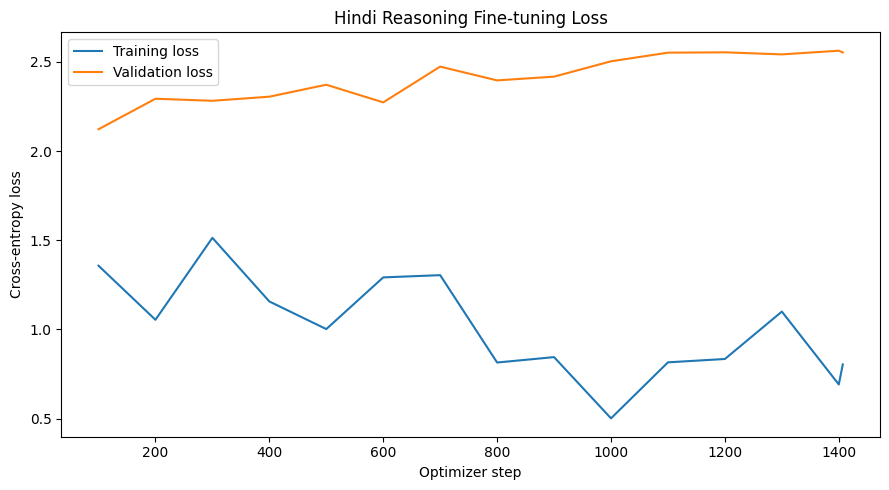

In [16]:
if history["step"]:
    plt.figure(figsize=(9, 5))
    plt.plot(history["step"], history["train_loss"], label="Training loss")
    plt.plot(history["step"], history["val_loss"], label="Validation loss")
    plt.xlabel("Optimizer step")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{INFO['name']} Reasoning Fine-tuning Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_OUT / "finetuning_loss.png", dpi=180)
    plt.show()

## 10. Post-fine-tuning reasoning evaluation

Use the exact same test set and decoding procedure as the pretrained baseline.

In [17]:
finetuned_acc, finetuned_task_acc, finetuned_difficulty_acc, finetuned_records = evaluate_reasoning(test_rows)

print(f"Fine-tuned overall accuracy: {finetuned_acc * 100:.2f}%")
for task in sorted(finetuned_task_acc):
    print(f"  {task:15s}: {finetuned_task_acc[task] * 100:.2f}%")

print("\nBy difficulty:")
for diff in sorted(finetuned_difficulty_acc):
    print(f"  {diff:8s}: {finetuned_difficulty_acc[diff] * 100:.2f}%")

print("\nComparison:")
print(f"{'Metric':20s} {'Pretrained':>12s} {'Fine-tuned':>12s} {'Delta':>12s}")
print("-" * 60)
print(
    f"{'Overall accuracy':20s} "
    f"{baseline_acc * 100:11.2f}% "
    f"{finetuned_acc * 100:11.2f}% "
    f"{(finetuned_acc - baseline_acc) * 100:+11.2f} pp"
)

comparison = {}
for task in sorted(set(r["task_type"] for r in test_rows)):
    b = baseline_task_acc.get(task, 0.0)
    f = finetuned_task_acc.get(task, 0.0)
    comparison[task] = {
        "pretrained": b,
        "finetuned": f,
        "delta": f - b,
    }
    print(
        f"{task:20s} "
        f"{b * 100:11.2f}% "
        f"{f * 100:11.2f}% "
        f"{(f - b) * 100:+11.2f} pp"
    )

difficulty_comparison = {}
for diff in sorted(set(baseline_difficulty_acc) | set(finetuned_difficulty_acc)):
    b = baseline_difficulty_acc.get(diff, 0.0)
    f = finetuned_difficulty_acc.get(diff, 0.0)
    difficulty_comparison[diff] = {
        "pretrained": b,
        "finetuned": f,
        "delta": f - b,
    }
    print(
        f"{diff:20s} "
        f"{b * 100:11.2f}% "
        f"{f * 100:11.2f}% "
        f"{(f - b) * 100:+11.2f} pp"
    )


100%|██████████| 1000/1000 [00:36<00:00, 27.22it/s]

Fine-tuned overall accuracy: 6.50%
  algebra        : 0.00%
  arithmetic     : 0.00%
  common_sense   : 0.00%
  comparison     : 22.86%
  counting       : 5.00%
  logic          : 0.00%
  multi_hop      : 3.33%
  percentage     : 0.00%
  physics_density: 4.00%
  physics_fma    : 0.00%
  physics_work   : 0.00%
  ratio          : 14.29%
  speed_distance : 25.71%
  transitive     : 0.00%
  unit_conversion: 20.00%

By difficulty:
  easy    : 6.37%
  hard    : 8.35%
  medium  : 4.82%

Comparison:
Metric                 Pretrained   Fine-tuned        Delta
------------------------------------------------------------
Overall accuracy            0.40%        6.50%       +6.10 pp
algebra                     0.00%        0.00%       +0.00 pp
arithmetic                  0.00%        0.00%       +0.00 pp
common_sense                0.00%        0.00%       +0.00 pp
comparison                  5.71%       22.86%      +17.14 pp
counting                    0.00%        5.00%       +5.00 pp
logic     

In [18]:
# Save quantitative results.
results = {
    "language": LANG,
    "test_size": len(test_rows),
    "pretrained_accuracy": baseline_acc,
    "finetuned_accuracy": finetuned_acc,
    "absolute_accuracy_delta": finetuned_acc - baseline_acc,
    "pretrained_task_accuracy": baseline_task_acc,
    "finetuned_task_accuracy": finetuned_task_acc,
    "pretrained_difficulty_accuracy": baseline_difficulty_acc,
    "finetuned_difficulty_accuracy": finetuned_difficulty_acc,
    "task_comparison": comparison,
    "difficulty_comparison": difficulty_comparison,
    "generation_max_new_tokens": GEN_MAX_NEW_TOKENS,
}

with open(METRIC_OUT / "reasoning_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

with open(METRIC_OUT / "baseline_predictions.jsonl", "w", encoding="utf-8") as f:
    for row in baseline_records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

with open(METRIC_OUT / "finetuned_predictions.jsonl", "w", encoding="utf-8") as f:
    for row in finetuned_records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Saved metrics and predictions to:", METRIC_OUT)


Saved metrics and predictions to: /kaggle/working/phase3_hi/metrics


## 11. Qualitative error analysis

Show successful and failed examples before and after fine-tuning. These examples are useful in the final report because the assignment asks for qualitative successes/failures and error analysis.

In [19]:
merged = []

for b, f in zip(baseline_records, finetuned_records):
    merged.append({
        "id": b["id"],
        "task_type": b["task_type"],
        "question": next(r["question"] for r in test_rows if r["id"] == b["id"]),
        "answer": b["answer"],
        "pretrained": b["prediction"],
        "pretrained_correct": b["correct"],
        "finetuned": f["prediction"],
        "finetuned_correct": f["correct"],
    })

print("=== Improvements ===")
shown = 0
for r in merged:
    if not r["pretrained_correct"] and r["finetuned_correct"]:
        print("\n", r["task_type"])
        print("Q:", r["question"])
        print("Gold:", r["answer"])
        print("Before:", r["pretrained"])
        print("After :", r["finetuned"])
        shown += 1
        if shown >= 8:
            break

print("\n=== Remaining failures ===")
shown = 0
for r in merged:
    if not r["finetuned_correct"]:
        print("\n", r["task_type"])
        print("Q:", r["question"])
        print("Gold:", r["answer"])
        print("Before:", r["pretrained"])
        print("After :", r["finetuned"])
        shown += 1
        if shown >= 8:
            break

=== Improvements ===

 ratio
Q: अमित और प्रिया की उम्र का अनुपात 2:3 है। यदि अमित की उम्र 24 वर्ष है, तो प्रिया की उम्र कितनी है?
Gold: 36
Before: - प्रिया की उम्र कितनी है ?
After : 36 वर्ष की 48 घंटे 60

 speed_distance
Q: एक कार 50 किलोमीटर प्रति घंटा की गति से चलती है। 5 घंटे में वह कितनी दूरी तय करेगी?
Gold: 250
Before: - यह एक कार है जो एक
After : 250 000 से 250 000 से 250

 comparison
Q: अमित का मान 31 है और मोहन का मान 16 है। इनमें से छोटा कौन है?
Gold: मोहन
Before: उत्तर : उत्तर : उत्तर : उत्तर
After : मोहन का मान 31 है , मोहन

 counting
Q: 11 वस्तुओं में से 10 वस्तुएँ चुननी हैं। यदि क्रम मायने नहीं रखता, तो कितने चयन संभव हैं?
Gold: 11
Before: - - - - - - -
After : 11 वस्तुओं में से 22 - 33

 physics_density
Q: एक वस्तु का द्रव्यमान 121 ग्राम और घनत्व 11 ग्राम प्रति घन सेंटीमीटर है। उसका आयतन कितना है?
Gold: 11
Before: - यह एक वस्तु है जो एक
After : 11 9 11 9 11 9 11

 unit_conversion
Q: 25 लीटर में कितने मिलीलीटर होते हैं?
Gold: 25000
Before: - पेट्रोल - डीजल के दाम में
Afte

## 12. Attention analysis

The supplied model returns one attention tensor per Transformer block when `return_attention=True`.

We compare:

- one early layer
- one late layer
- multiple heads
- pretrained vs. fine-tuned

We also compute:

\[
H = -\sum_j p_j \log p_j
\]

for attention entropy, and

\[
D = \sum_j p_j |i-j|
\]

for mean attention distance.

Higher entropy indicates more diffuse attention. Larger mean distance indicates more long-range attention.

In [20]:
def attention_stats(attn):
    # attn: [B, H, T, T]
    p = attn.clamp_min(1e-12)

    entropy = -(p * p.log()).sum(dim=-1)  # [B,H,T]

    T = attn.size(-1)
    positions = torch.arange(T, device=attn.device)
    distance = (positions[None, :] - positions[:, None]).abs().float()
    mean_distance = (attn * distance).sum(dim=-1)  # [B,H,T]

    return (
        entropy.mean(dim=(0, 2)).detach().cpu().numpy(),
        mean_distance.mean(dim=(0, 2)).detach().cpu().numpy(),
    )

def get_attention_for_row(model_obj, row):
    prompt, _ = format_example(row)
    ids = encode_text(prompt)

    ids = ids[-CONTEXT_LEN:]
    x = torch.tensor([ids], dtype=torch.long, device=DEVICE)

    model_obj.eval()
    with torch.no_grad():
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=amp_dtype,
            enabled=use_amp,
        ):
            _, _, maps = model_obj(
                x,
                return_attention=True,
            )

    return ids, maps

def reload_model_checkpoint(path):
    ck = torch.load(path, map_location="cpu")
    m = GPTLanguageModel(
        vocab_size=CKPT_VOCAB_SIZE,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        n_layers=N_LAYERS,
        d_ff=D_FF,
        context_len=CONTEXT_LEN,
        dropout=0.1,
        pad_token_id=PAD_ID,
    )
    m.load_state_dict(ck["model"], strict=True)
    return m.to(DEVICE)

# Reconstruct the original pretrained model so the comparison is genuine.
pretrained_model = reload_model_checkpoint(CKPT_PATH)
finetuned_model = reload_model_checkpoint(CKPT_OUT / "final.pt")

attention_row = test_rows[0]
print("Attention example:")
print(attention_row["question"])
print("Gold:", attention_row["answer"])

Attention example:
एक मशीन 26 वाट की शक्ति से 26 सेकंड चलती है। उसने कितना कार्य किया?
Gold: 676


/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

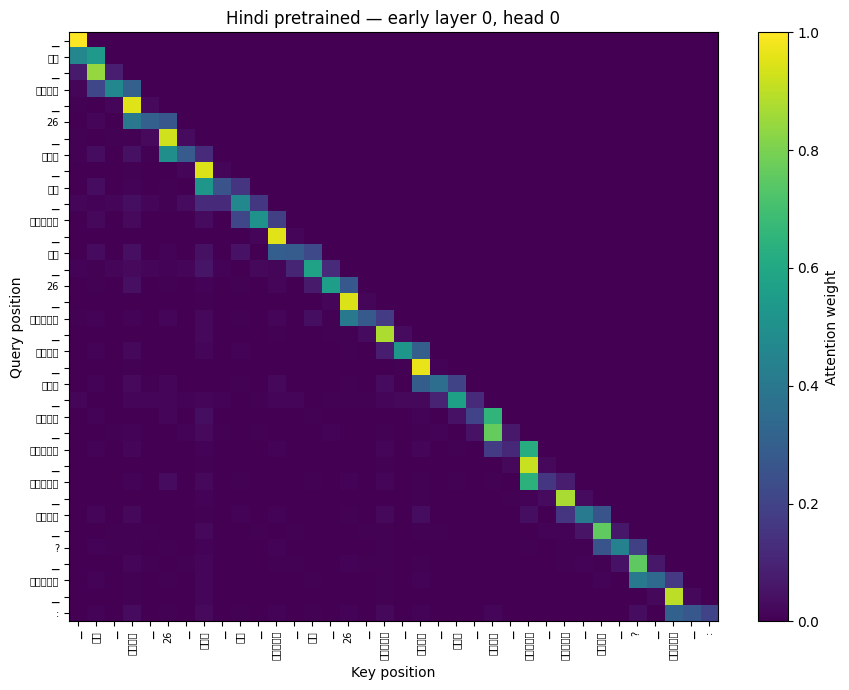

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

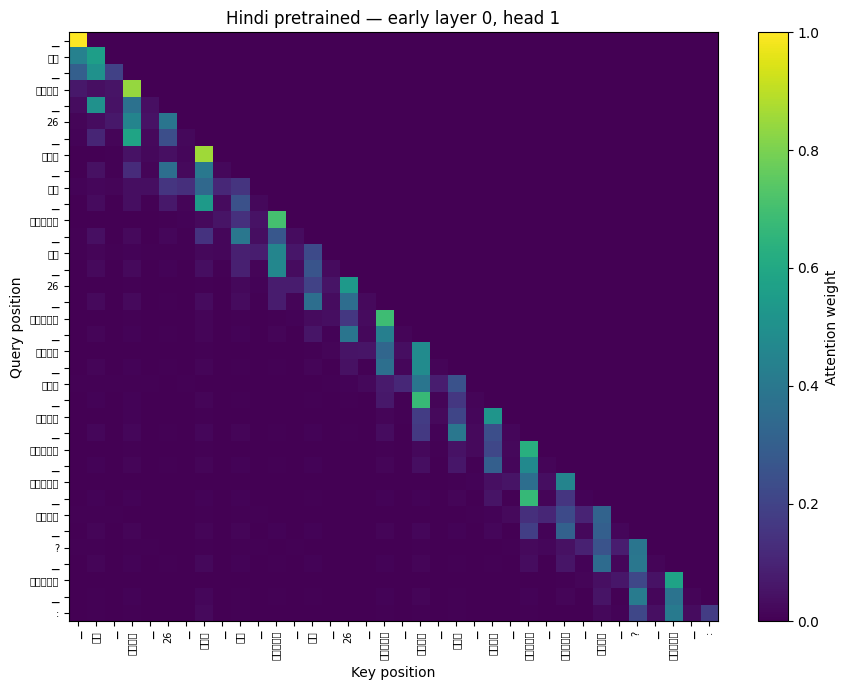

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

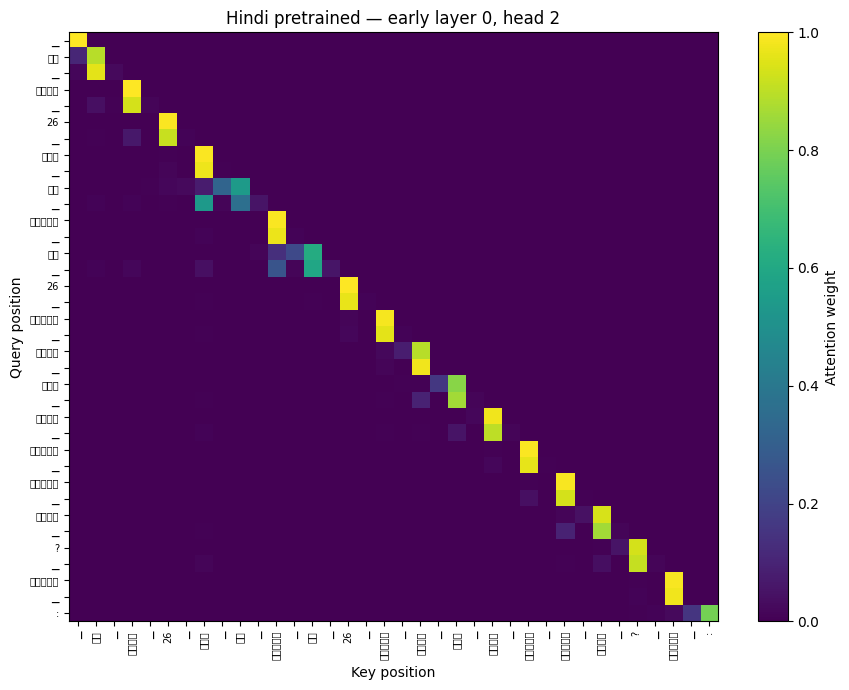

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

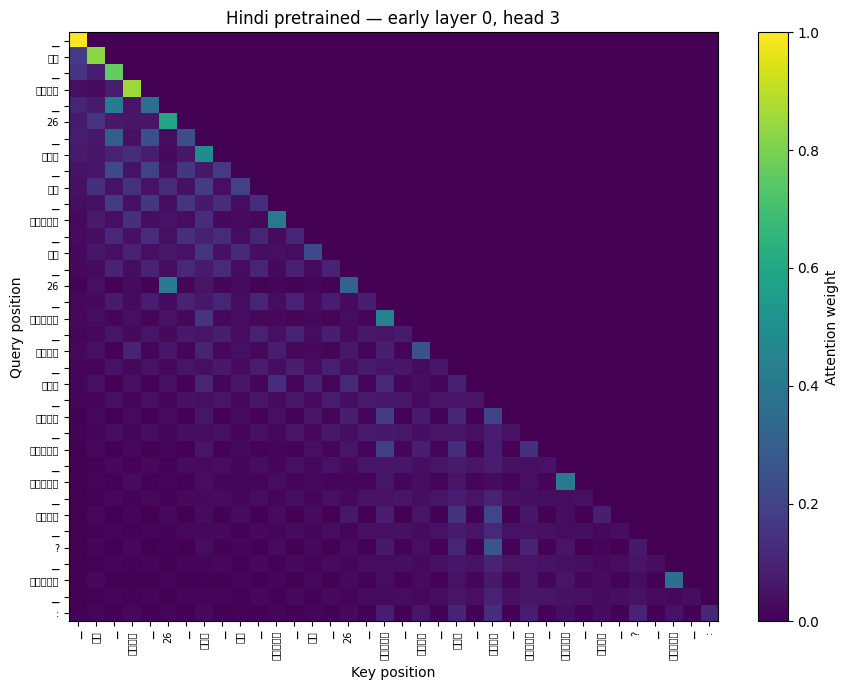

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

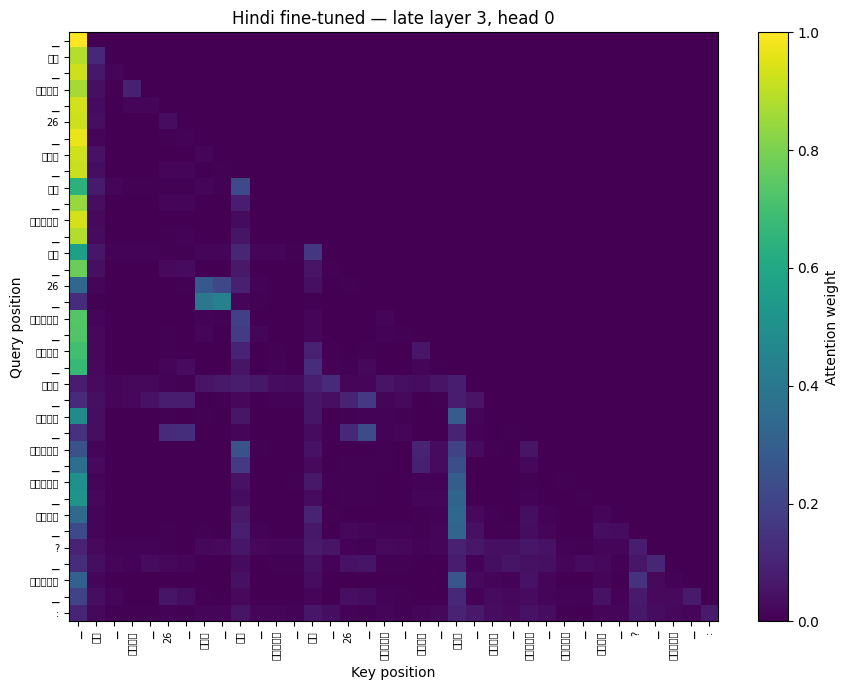

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

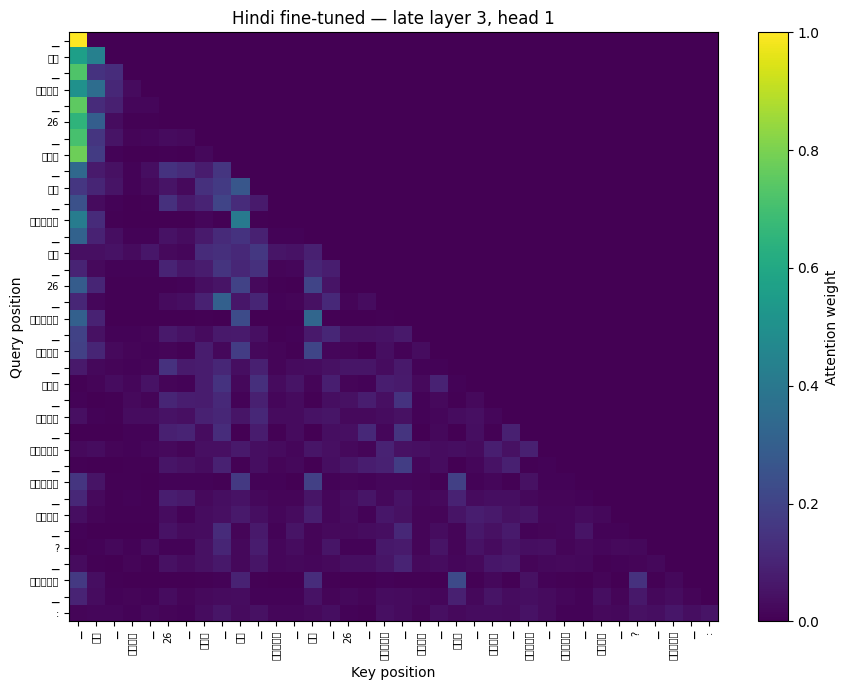

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

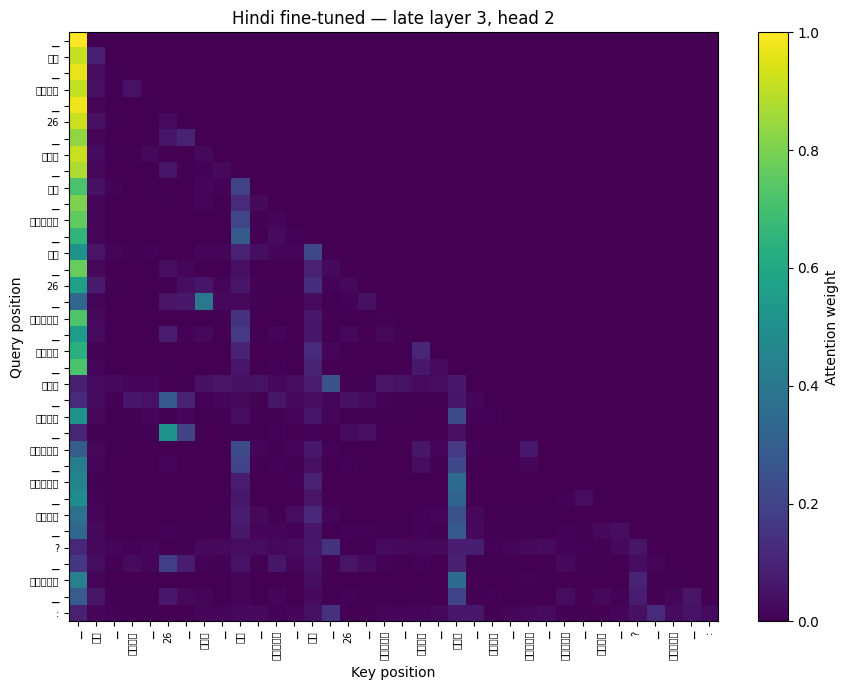

/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2181525150.py:32: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

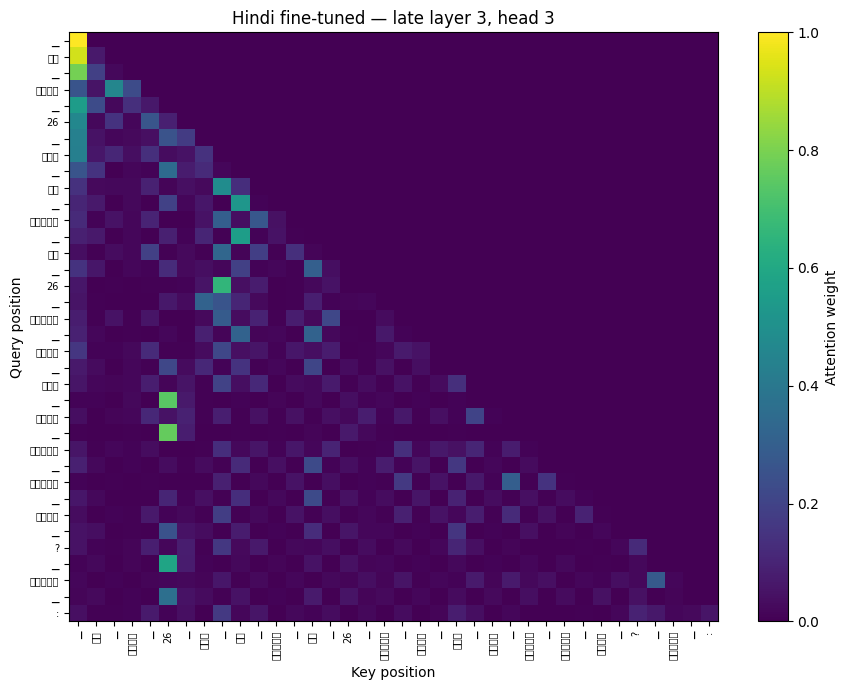

In [21]:
def token_labels(ids):
    labels = []
    for i in ids:
        labels.append(ID_TO_TOKEN.get(int(i), "?"))
    return labels

def plot_attention(model_obj, row, layer_idx, head_idx, title, filename):
    ids, maps = get_attention_for_row(model_obj, row)
    layer_idx = min(layer_idx, len(maps) - 1)

    attn = maps[layer_idx][0].detach().float().cpu()

    # Dropout is disabled in eval mode, but the model can still return
    # probabilities with tiny numerical differences across runs.
    matrix = attn[head_idx].numpy()

    labels = token_labels(ids)

    plt.figure(figsize=(9, 7))
    plt.imshow(matrix, aspect="auto")
    plt.colorbar(label="Attention weight")
    plt.xlabel("Key position")
    plt.ylabel("Query position")
    plt.title(title)

    n = len(labels)
    step = max(1, n // 20)
    ticks = list(range(0, n, step))
    plt.xticks(ticks, [labels[i] for i in ticks], rotation=90, fontsize=7)
    plt.yticks(ticks, [labels[i] for i in ticks], fontsize=7)

    plt.tight_layout()
    plt.savefig(PLOT_OUT / filename, dpi=180)
    plt.show()

early_layer = 0
late_layer = N_LAYERS - 1

for head in range(min(4, N_HEADS)):
    plot_attention(
        pretrained_model,
        attention_row,
        early_layer,
        head,
        f"{INFO['name']} pretrained — early layer {early_layer}, head {head}",
        f"pretrained_early_L{early_layer}_H{head}.png",
    )

for head in range(min(4, N_HEADS)):
    plot_attention(
        finetuned_model,
        attention_row,
        late_layer,
        head,
        f"{INFO['name']} fine-tuned — late layer {late_layer}, head {head}",
        f"finetuned_late_L{late_layer}_H{head}.png",
    )

In [22]:
# Aggregate entropy and mean-distance statistics over several test examples.
N_ATTENTION_SAMPLES = min(32, len(test_rows))

def aggregate_attention_metrics(model_obj, rows):
    entropies = []
    distances = []

    for row in rows:
        _, maps = get_attention_for_row(model_obj, row)

        layer_ent = []
        layer_dist = []

        for attn in maps:
            e, d = attention_stats(attn.float())
            layer_ent.append(e)
            layer_dist.append(d)

        entropies.append(np.stack(layer_ent))
        distances.append(np.stack(layer_dist))

    return np.mean(entropies, axis=0), np.mean(distances, axis=0)

pre_e, pre_d = aggregate_attention_metrics(
    pretrained_model,
    test_rows[:N_ATTENTION_SAMPLES],
)
ft_e, ft_d = aggregate_attention_metrics(
    finetuned_model,
    test_rows[:N_ATTENTION_SAMPLES],
)

# Layer/head summary tables as JSON.
attention_summary = {
    "pretrained_entropy": pre_e.tolist(),
    "pretrained_mean_distance": pre_d.tolist(),
    "finetuned_entropy": ft_e.tolist(),
    "finetuned_mean_distance": ft_d.tolist(),
}

with open(METRIC_OUT / "attention_summary.json", "w", encoding="utf-8") as f:
    json.dump(attention_summary, f, indent=2)

print("Layer/head attention summary")
for layer in range(N_LAYERS):
    print(
        f"L{layer}: "
        f"pre entropy={pre_e[layer].mean():.4f}, "
        f"ft entropy={ft_e[layer].mean():.4f}, "
        f"pre distance={pre_d[layer].mean():.4f}, "
        f"ft distance={ft_d[layer].mean():.4f}"
    )

Layer/head attention summary
L0: pre entropy=1.3371, ft entropy=1.3817, pre distance=3.3378, ft distance=3.7554
L1: pre entropy=2.1619, ft entropy=2.0826, pre distance=6.8995, ft distance=9.2473
L2: pre entropy=1.8440, ft entropy=1.9361, pre distance=8.1703, ft distance=9.6221
L3: pre entropy=1.7417, ft entropy=1.7616, pre distance=11.8806, ft distance=11.9002


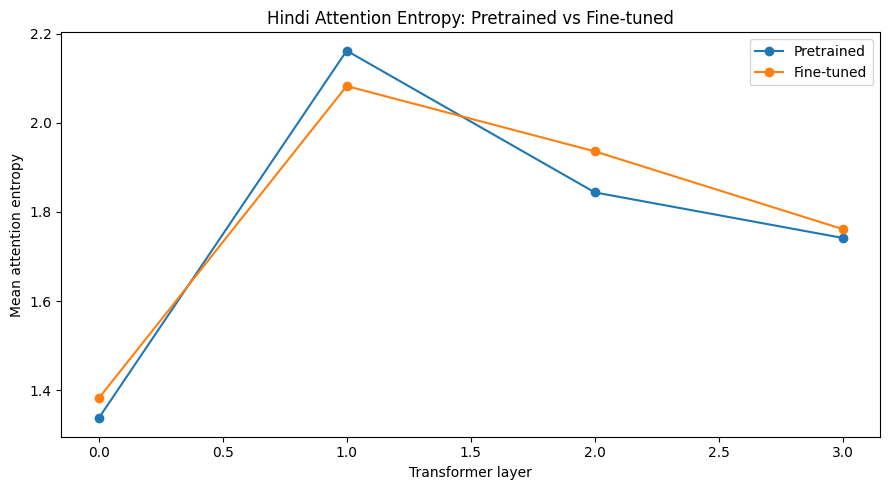

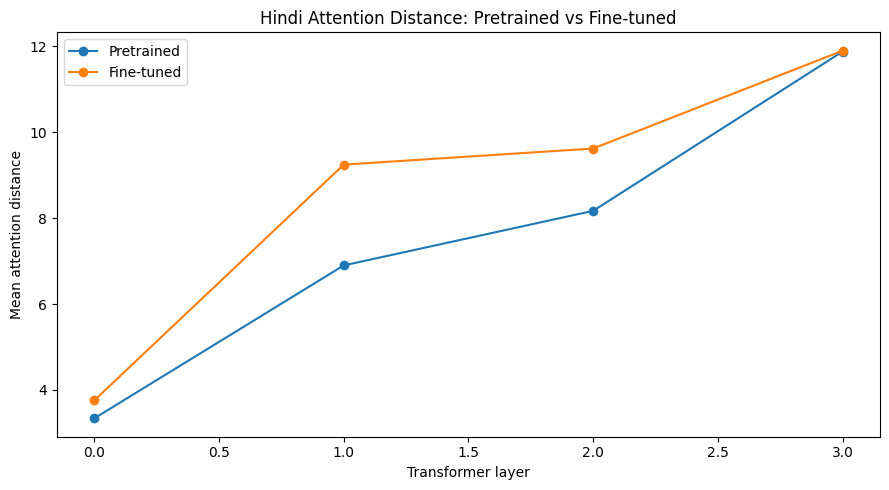

In [23]:
# Plot layer-level mean entropy and distance.
layers = np.arange(N_LAYERS)

plt.figure(figsize=(9, 5))
plt.plot(layers, pre_e.mean(axis=1), marker="o", label="Pretrained")
plt.plot(layers, ft_e.mean(axis=1), marker="o", label="Fine-tuned")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention entropy")
plt.title(f"{INFO['name']} Attention Entropy: Pretrained vs Fine-tuned")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_OUT / "attention_entropy_comparison.png", dpi=180)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(layers, pre_d.mean(axis=1), marker="o", label="Pretrained")
plt.plot(layers, ft_d.mean(axis=1), marker="o", label="Fine-tuned")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention distance")
plt.title(f"{INFO['name']} Attention Distance: Pretrained vs Fine-tuned")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_OUT / "attention_distance_comparison.png", dpi=180)
plt.show()

## 13. Final artifact summary

Everything needed for Phase 3 is now under:

```text
/kaggle/working/phase3_<lang>/
├── checkpoints/
│   ├── step_*.pt
│   ├── last.pt
│   └── final.pt
├── metrics/
│   ├── reasoning_results.json
│   ├── baseline_predictions.jsonl
│   ├── finetuned_predictions.jsonl
│   └── attention_summary.json
├── plots/
│   ├── finetuning_loss.png
│   ├── attention_entropy_comparison.png
│   ├── attention_distance_comparison.png
│   └── attention heatmaps...
├── logs/
├── src/
│   ├── model.py
│   └── tokenizers.py
└── finetune_config.json

In [24]:
print("Phase 3 artifacts:")
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(OUT)}  ({path.stat().st_size / 1024:.1f} KB)")

print("\nFINAL RESULT")
print(f"Language: {INFO['name']}")
print(f"Pretrained accuracy: {baseline_acc * 100:.2f}%")
print(f"Fine-tuned accuracy: {finetuned_acc * 100:.2f}%")
print(f"Improvement: {(finetuned_acc - baseline_acc) * 100:+.2f} percentage points")

Phase 3 artifacts:
checkpoints/final.pt  (288008.4 KB)
checkpoints/last.pt  (288008.1 KB)
checkpoints/step_000100.pt  (288022.6 KB)
checkpoints/step_000200.pt  (288022.7 KB)
checkpoints/step_000300.pt  (288022.7 KB)
checkpoints/step_000400.pt  (288022.7 KB)
checkpoints/step_000500.pt  (288022.7 KB)
checkpoints/step_000600.pt  (288022.8 KB)
checkpoints/step_000700.pt  (288022.8 KB)
checkpoints/step_000800.pt  (288022.9 KB)
checkpoints/step_000900.pt  (288022.9 KB)
checkpoints/step_001000.pt  (288022.9 KB)
checkpoints/step_001100.pt  (288022.9 KB)
checkpoints/step_001200.pt  (288023.0 KB)
checkpoints/step_001300.pt  (288023.0 KB)
checkpoints/step_001400.pt  (288023.1 KB)
checkpoints/step_001407.pt  (288023.1 KB)
finetune_config.json  (0.3 KB)
metrics/attention_summary.json  (1.9 KB)
metrics/baseline_predictions.jsonl  (201.5 KB)
metrics/finetuned_predictions.jsonl  (192.3 KB)
metrics/reasoning_results.json  (3.2 KB)
plots/attention_distance_comparison.png  (80.1 KB)
plots/attention_entro